In [1]:
import pandas as pd

import numpy as np

from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import PandasTools as pdt
from rdkit.Chem import GraphDescriptors
from rdkit.Chem import rdFMCS as fmcs

In [4]:
# consolidate_data
# inputs:
#  sdfs - 1d array of filenames for SDF files
#  userinputs - 2d array of key value pairs for additional user parameters for each SDF file
#  dropcols - 1d array of columns to drop from the loaded SDF files
# returns:
#  dataframe which concatenates all loaded SDF files
def consolidate_data(
    sdfs, 
    userinputs=[],
    dropcols=[]#['CdId','Mol Weight','Formula','target_id','target_name','organism','target_type','ID','std_unit','std_type']
    ):
    
    sdf_df_aggregate = []
    for i in range(len(sdfs)):
        temp = pdt.LoadSDF(sdfs[i], embedProps=True, molColName=None, smilesName='smiles').drop(dropcols,axis=1)
        for additional_labels in userinputs[i]:
            temp[additional_labels[0]] = additional_labels[1]
        sdf_df_aggregate.append(temp)
    
    return pd.concat(sdf_df_aggregate).reset_index(drop=True)

# export_data
# inputs:
#  data - consolidated dataframe to export
#  filename - filename of exported data
# returns:
#  nothing.
def export_data(data,filename):
    data.to_csv(filename)

In [5]:
temp_df = consolidate_data(['proper_sdf/CHEMBL2147.sdf','proper_sdf/CHEMBL2343.sdf','proper_sdf/CHEMBL5794.sdf'],[[('target','threonine-protein kinase PIM1')],[('target','threonine-protein kinase Sgk1')],[('target','threonine-protein kinase Sgk2')]])

In [6]:
temp_df

,chembl_id,chembl_pref_name,ID,smiles,target
0,CHEMBL551064,AEW-541,,Nc1ncnc2c1c(-c1cccc(OCc3ccccc3)c1)cn2[C@H]1C[C...,threonine-protein kinase PIM1
1,CHEMBL1088752,LOSMAPIMOD,,Cc1c(F)cc(C(=O)NC2CC2)cc1-c1ccc(C(=O)NCC(C)(C)...,threonine-protein kinase PIM1
2,CHEMBL3188267,CAPMATINIB,,CNC(=O)c1ccc(-c2cnc3ncc(Cc4ccc5ncccc5c4)n3n2)cc1F,threonine-protein kinase PIM1
3,CHEMBL3991927,HMN-214,,COc1ccc(S(=O)(=O)N(C(C)=O)c2ccccc2/C=C/c2cc[n+...,threonine-protein kinase PIM1
4,CHEMBL475251,R-406,,COc1cc(Nc2ncc(F)c(Nc3ccc4c(n3)NC(=O)C(C)(C)O4)...,threonine-protein kinase PIM1
...,...,...,...,...,...
10398,CHEMBL253969,OSI-632,,NC(=O)c1c(OCc2c(F)cc(Br)cc2F)nsc1NC(=O)NCCCCN1...,threonine-protein kinase Sgk2
10399,CHEMBL101253,VATALANIB,,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,threonine-protein kinase Sgk2
10400,CHEMBL1289494,TIVOZANIB,,COc1cc2nccc(Oc3ccc(NC(=O)Nc4cc(C)on4)c(Cl)c3)c...,threonine-protein kinase Sgk2
10401,CHEMBL941,IMATINIB,,Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc...,threonine-protein kinase Sgk2


In [7]:
export_data(temp_df,"export_test.csv")

In [8]:
# przygotowanie danych poprzez skalowanie
# jeżeli dane mają dystrybucję normalną
def gaussianScaler(numArr):
    # standard gaussian scaler
    # X' = (X-mu)/sigma
    mean = numArr.mean()
    std = numArr.std()
    numArr = (numArr - mean) / std
    return numArr

# jeżeli dane podążają za 'power law' (~e^x)
def logScaler(numArr):
    # standard logarythmic scaler
    numArr = np.log(numArr)
    return numArr

# jeżeli dystrybucja jest niejasna
# dane dzielimy na kwantyle
def createQuantiles(dfColumn, numQuantiles):
    # create as many quantiles as wanted
    return pd.qcut(dfColumn, numQuantiles, labels=False, duplicates='drop')

# i normalizujemy minmaxem
def minMaxScaler(numArr):
    # standard minmax scaler
    minx = np.min(numArr)
    maxx = np.max(numArr)
    # linearly map all values from minimal to maximal
    # to values ranging from 0 to 1
    numArr = (numArr - minx) / (maxx - minx)
    return numArr

class Featurizer:
    def __init__(self, smiles_col='smiles', activity_col='std_value', **kwargs):
        self.smiles_col = smiles_col
        self.activity_col = activity_col
        self.__dict__.update(kwargs)
    
    def __call__(self, df):
        raise NotImplementedError()

class ClusteringFeaturizer(Featurizer):
    def __init__(self, activity_dist='gaussian', qcount=0, radius=2, length=1024, **kwargs):
        self.activity_dist = activity_dist
        self.qcount = qcount
        self.radius = radius
        self.length = length
        super().__init__(**kwargs)
    
    def __call__(self, df,quick=False):
        ## check if valid arguments
        # check activity distribution
        if(self.activity_dist != 'gaussian' and self.activity_dist != 'powerlaw' and self.activity_dist != 'quantiles'):
            print('wrongly set attribute activity_dist. Please use one of the following:\ngaussian, powerlaw, quantiles')
            return pd.DataFrame()
        # if quantiles are selected, there must be at least two of them
        if(self.activity_dist == 'quantiles' and self.qcount < 2):
            print('wrongly set quantile count.')
            return pd.DataFrame()
        # reconvert everything to float in order to prepare for scaling
        #df[self.activity_col] = df[self.activity_col].astype(float)
        # generate column names for features in morgan fingerprints
        c = ['f_'+str(n) for n in np.arange(self.length)]
        ## quick will eat more memory
        if quick:
            features = []
        else:
            features = pd.DataFrame(columns=c)
        ## prepare activity by scaling the data with scaler
        # chosen to the selected distribution
        #match self.activity_dist:
        #    case 'gaussian':
        #        df[self.activity_col] = gaussianSacler(df[self.activity_col])
        #    case 'powerlaw':
        #        df[self.activity_col] = logScaler(df[self.activity_col])
        #    case 'quantiles':
        #        df[self.activity_col] = createQuantiles(df[self.activity_col], self.qcount)
        #        df[self.activity_col] = minMaxScaler(df[self.activity_col])
        #    case _:
                #do nothing
        #        return
        ## generate features
        for i, row in df.iterrows():
            smiles = row[self.smiles_col]
            #activity = row[self.activity_col]
            mol = Chem.MolFromSmiles(smiles)
            fp = AllChem.GetMorganFingerprintAsBitVect(mol, self.radius, nBits=self.length)
            # vector containing morgan fingerprints
            fpvector = np.array(fp,dtype=int)
            # vector representing the molecule, contains
            # fingerprints and activity in floats
            vec = np.array([np.hstack(fpvector)],dtype=float)
            if quick:
                features.append(vec)
            else:
                fta = pd.DataFrame(vec,columns=c)
                features = pd.concat([features,fta],ignore_index=True)
        return features

In [9]:
datas = temp_df
feature_count = 1024
quantile_count = 100
featurizer = ClusteringFeaturizer(activity_dist='quantiles',qcount=quantile_count,length=feature_count)
feature_count = (feature_count) * 1.0 # + activity ; konwersja na float
datas = featurizer(datas)

[16:32:28] DEPRECATION WARNING: please use MorganGenerator
C:\Users\limep\AppData\Local\Temp\ipykernel_5312\234481801.py:97: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  features = pd.concat([features,fta],ignore_index=True)
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGenerator
[16:32:28] DEPRECATION WARNING: please use MorganGen

In [10]:
export_data(datas,"export_processed.csv")

In [11]:
datas

,f_0,f_1,f_2,f_3,f_4,f_5,f_6,f_7,f_8,f_9,...,f_1014,f_1015,f_1016,f_1017,f_1018,f_1019,f_1020,f_1021,f_1022,f_1023
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10398,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10399,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10400,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10401,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
import seaborn as sns

from matplotlib import pyplot as plt

from sklearn.cluster import BisectingKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import ipywidgets

def cluster(dataset,n):
    clustering = BisectingKMeans(n_clusters=n)
    clusterdist = clustering.fit_transform(dataset)
    clusterid = clustering.labels_
    clusterdist = clusterdist[np.arange(len(dataset)),clusterid]
    processed_data = dataset.copy()
    processed_data['centroid'] = clusterid
    processed_data['distance'] = clusterdist
    pca = PCA(n_components=3)
    pcdata3d = pd.DataFrame(pca.fit_transform(processed_data.drop(["centroid","distance"], axis=1)))
    pcdata3d.columns = ["pc1", "pc2", "pc3"]

    sizes = np.power(10,6)/np.power(processed_data["distance"],7)
    fig = plt.figure(figsize=(11,9))
    ax = fig.add_subplot(projection='3d')
    ax.azim = 35
    ax.elev = 35
    sc = ax.scatter(pcdata3d["pc1"],pcdata3d["pc2"],pcdata3d["pc3"],cmap=plt.cm.gist_rainbow,c=processed_data["centroid"],s=sizes)
    plt.legend(*sc.legend_elements(), bbox_to_anchor=(1.05, 1), loc=2)
    plt.show()
    return clustering, processed_data, pcdata3d

def showcluster(cid,dat,pcdat):
    cdata = dat[dat["centroid"]==cid]['distance']
    pickcluster = pcdat.loc[dat["centroid"]==cid]
    sizes = np.power(10,6)/np.power(cdata,7)
    print(sizes.shape)
    print(pickcluster.shape)
    fig = plt.figure(figsize=(10,10))
    ax = fig.add_subplot(projection='3d')
    ax.azim = 35
    ax.elev = 35
    sc = ax.scatter(pickcluster["pc1"],pickcluster["pc2"],pickcluster["pc3"],cmap=plt.cm.viridis,s=sizes)
    plt.legend(*sc.legend_elements(), bbox_to_anchor=(1.05, 1), loc=2)


In [13]:
def getAtoms(df):
    mols = []
    for row in df:
        smiles = row
        mol = Chem.MolFromSmiles(smiles)
        mols.append(mol)
    return mols

def findmcs(cid,dat,ogdat):
    centroid = dat.loc[dat['centroid'] == cid, :]
    smilesss = ogdat.loc[dat['centroid']==cid, :]
    act = smilesss['std_value']
    dst = centroid['distance']
    mol = smilesss['smiles'][:10]
    if (mol.empty or mol.size < 2):
        print("cluster did not converge close enough")
        #plt.scatter(dst,act)
        #plt.show()
    else:
        mol = mol.reset_index(drop=True)
        #print(mol)
        mcs = Chem.MolFromSmarts(fmcs.FindMCS(getAtoms(mol),timeout=1).smartsString)
        #plt.scatter(dst,act)
        #plt.show()
        img = Chem.Draw.MolToImage(mcs)
        return img

In [14]:
from ipywidgets import interact

def show_molecule(smiles=''):
    if not smiles:
        return
    mol = Chem.MolFromSmiles(smiles)
    display(mol)
    if not mol:
        return
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)
    mblock = Chem.MolToMolBlock(mol, kekulize=False)

    # 3D VIEW:
    #view = py3Dmol.view(width=800, height=500)
    #view.addModel(Chem.MolToMolBlock(mol, kekulize=True), 'mol')
    #view.setStyle({'model': -1}, {"stick": {'color': 'white', 'radius': 0.15}, "sphere": {'radius': .4}})
    #view.zoomTo({'model': -1})
    #view.show()


def examine_cluster(dat,dat_sorted,cid,eid):    
    centroid = dat_sorted.loc[dat['centroid'] == cid, :]
    print(eid,"/",len(centroid))
    print(centroid['distance'].iloc[eid])
    mol = centroid['smiles']
    #mol = mol.reset_index()
    print(centroid['target'].iloc[eid])
    show_molecule(mol.iloc[eid])

In [15]:
def centroidanalysis(dat,ccount):
    dsts = []
    count = []
    for i in range(ccount):
        centroid = dat[dat['centroid']==i]
        dsts.append(np.sum(centroid['distance']))
        count.append(len(centroid))
    plt.scatter(count,dsts)
    plt.title("centroid count vs total distance")
    plt.xlabel("count")
    plt.ylabel("distance")
    plt.show()

def cal_centroidanalysis(dat,ccount):
    dsts = []
    count = []
    for i in range(ccount):
        centroid = dat[dat['centroid']==i]
        dsts.append(np.sum(centroid['distance']))
        count.append(len(centroid))
    return dsts, count

def ccount(dat,cs):
    count = []
    for i in range(cs):
        centroid = dat[dat['centroid']==i]
        count.append(len(centroid))
    plt.bar(range(cs),count)
    plt.title("centroid count")
    plt.xlabel("centroid")
    plt.ylabel("amount")
    plt.show()

def cal_ccount(dat,cs):
    count = []
    for i in range(cs):
        centroid = dat[dat['centroid']==i]
        count.append(len(centroid))
    return count

def perform_analysis(dat,n,og,adj=None,ogadj=None):
    cl, processed, pcadata = cluster(dat,n)
    ccount(processed,n)
    centroidanalysis(processed,n)
    dat_sorted = processed.copy()
    dat_sorted['smiles'] = og['smiles']
    dat_sorted['target'] = og['target']
    dat_sorted = dat_sorted.sort_values(by=['distance'])
    #adjoint = adj.copy()
    #nl = cl.predict(adjoint)
    #nd = cl.transform(adjoint)[np.arange(len(adjoint)),nl]
    #adjoint['centroid'] = nl
    #adjoint['distance'] = nd
    prevd, prevc = cal_centroidanalysis(processed,n)
    #newd, newc = cal_centroidanalysis(adjoint,n)
    #plt.scatter(newd,newc,c='red',marker='^')
    #plt.scatter(prevd,prevc,c='blue',marker='o')
    #plt.title("centroid count")
    #plt.xlabel("centroid")
    #plt.ylabel("amount")
    #plt.show()
    #plt.bar(range(n),newc,color='red')
    #plt.bar(range(n),prevc,color='blue')
    #plt.title("centroid count")
    #plt.xlabel("centroid")
    #plt.ylabel("amount")
    #plt.show()
    #adj_sorted = adjoint.copy()
    #adj_sorted['target'] = ogadj['target']
    #adj_sorted['smiles'] = ogadj['smiles']
    #adj_sorted = adj_sorted.sort_values(by=['distance'])
    return dat_sorted, None, processed, None

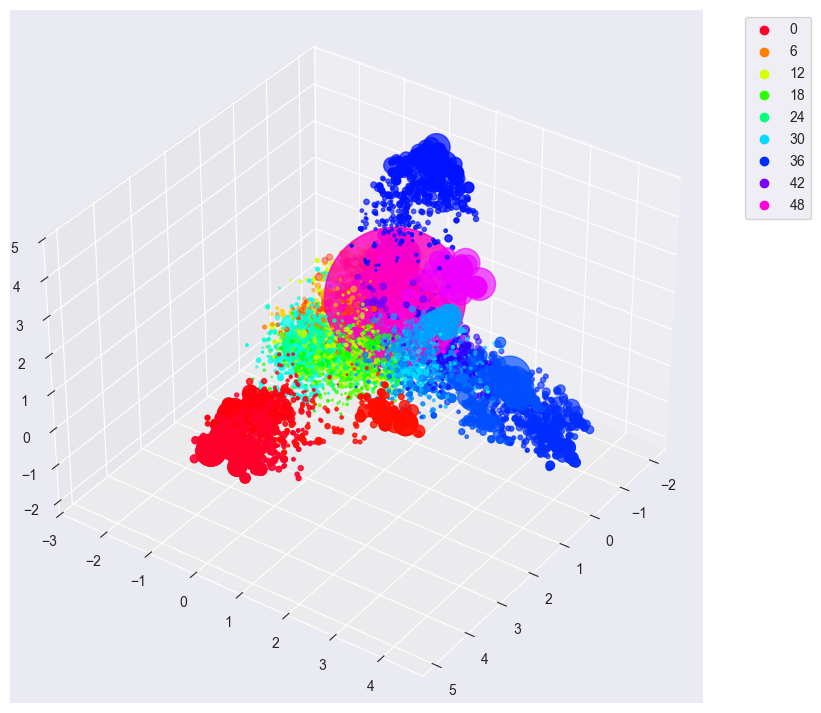

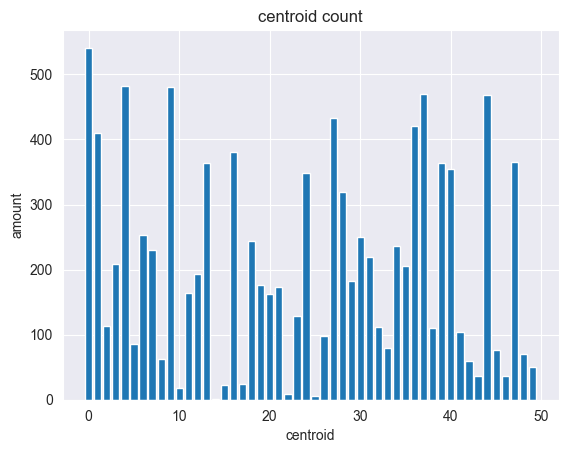

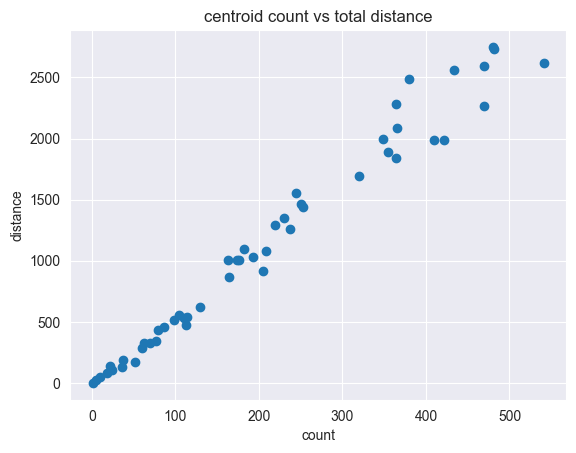

In [16]:
a1, a2, a3, a4 = perform_analysis(datas,50,temp_df)

In [17]:
def targettocolor(dat, n):
    pim1d, pim1c = cal_centroidanalysis(dat[dat['target'] == 'threonine-protein kinase PIM1'],n)
    sgk1d, sgk1c = cal_centroidanalysis(dat[dat['target'] == 'threonine-protein kinase Sgk1'],n)
    sgk2d, sgk2c = cal_centroidanalysis(dat[dat['target'] == 'threonine-protein kinase Sgk2'],n)
    plt.scatter(pim1d, pim1c, marker='^', c='red')
    plt.scatter(sgk1d, sgk1c, marker='o', c='blue')
    plt.scatter(sgk2d, sgk2c, marker='x', c='green')
    plt.title("centroid count")
    plt.xlabel("centroid")
    plt.ylabel("amount")
    plt.show()
    plt.bar(range(n),pim1c,color='red')
    plt.title("centroid count for pim1")
    plt.xlabel("centroid")
    plt.ylabel("amount")
    plt.show()
    plt.bar(range(n),sgk1c,color='blue')
    plt.title("centroid count for sgk1")
    plt.xlabel("centroid")
    plt.ylabel("amount")
    plt.show()
    plt.bar(range(n),sgk2c,color='green')
    plt.title("centroid count for sgk2")
    plt.xlabel("centroid")
    plt.ylabel("amount")
    plt.show()

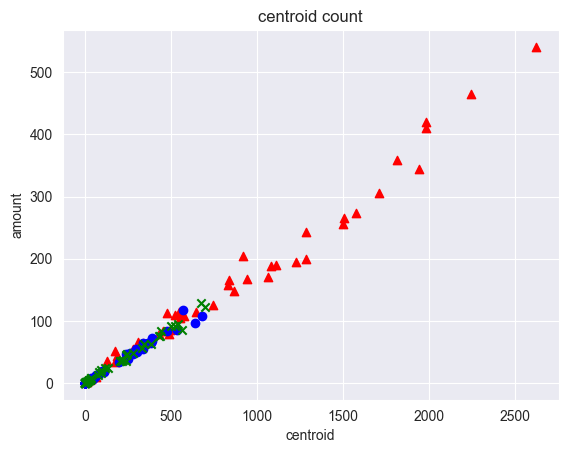

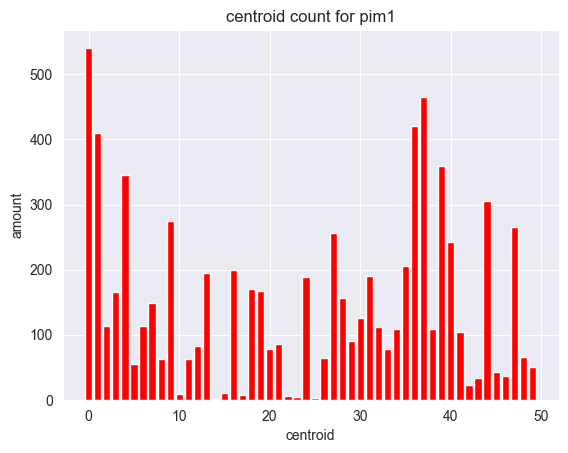

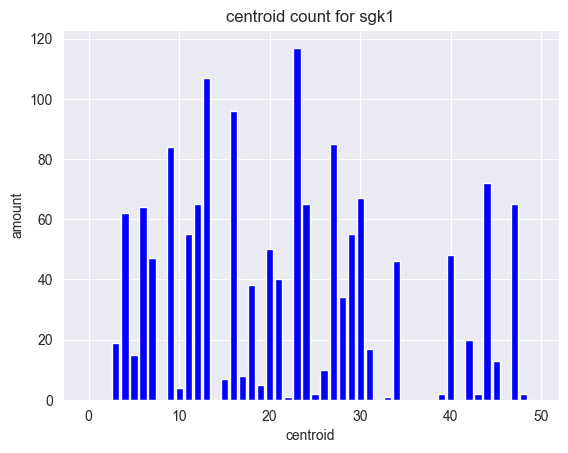

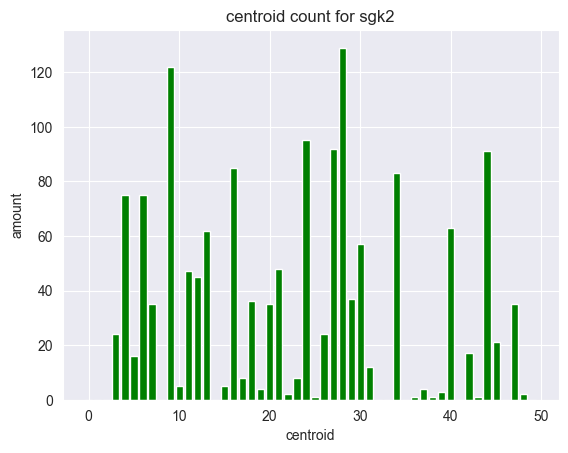

In [18]:
targettocolor(a1,50)

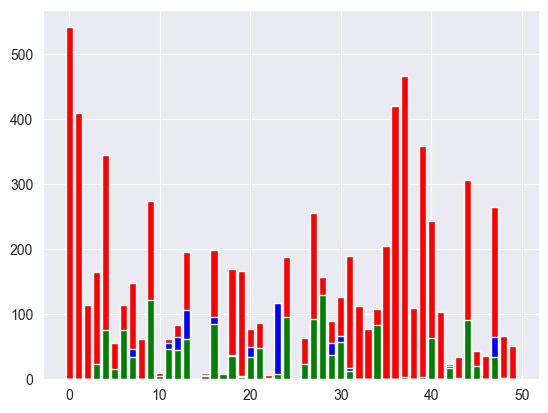

In [19]:
pim1d, pim1c = cal_centroidanalysis(a1[a1['target'] == 'threonine-protein kinase PIM1'],50)
sgk1d, sgk1c = cal_centroidanalysis(a1[a1['target'] == 'threonine-protein kinase Sgk1'],50)
sgk2d, sgk2c = cal_centroidanalysis(a1[a1['target'] == 'threonine-protein kinase Sgk2'],50)
plt.bar(range(50), pim1c, color='red')
plt.bar(range(50), sgk1c, color='blue')
plt.bar(range(50), sgk2c, color='green')
plt.show()

In [45]:
import numpy as np
from scipy.special import rel_entr, kl_div

eps = 1e-20

pim1c_norm = pim1c / np.sum(pim1c)
sgk1c_norm = sgk1c / np.sum(sgk1c)
sgk2c_norm = sgk2c / np.sum(sgk2c)

def kl_divergence(p, q):
    return np.sum(kl_div(p + eps, q + eps))

def bhattacharyya_distance(p, q):
    return -np.log(np.sum(np.sqrt(p * q)))

kl_pim1_sgk1 = kl_divergence(pim1c_norm, sgk1c_norm)
kl_pim1_sgk2 = kl_divergence(pim1c_norm, sgk2c_norm)
kl_sgk1_sgk2 = kl_divergence(sgk1c_norm, sgk2c_norm)

kl_sgk1_pim1 = kl_divergence(sgk1c_norm, pim1c_norm)
kl_sgk2_pim1 = kl_divergence(sgk2c_norm, pim1c_norm)
kl_sgk2_sgk1 = kl_divergence(sgk2c_norm, sgk1c_norm)

bhat_pim1_sgk1 = bhattacharyya_distance(pim1c_norm, sgk1c_norm)
bhat_pim1_sgk2 = bhattacharyya_distance(pim1c_norm, sgk2c_norm)
bhat_sgk1_sgk2 = bhattacharyya_distance(sgk1c_norm, sgk2c_norm)

print(f"KL(PIM1 || SGK1): {kl_pim1_sgk1}")
print(f"KL(PIM1 || SGK2): {kl_pim1_sgk2}")
print(f"KL(SGK1 || SGK2): {kl_sgk1_sgk2}")

print("-----------------------------------------")

print(f"KL(SGK1 || PIM1): {kl_sgk1_pim1}")
print(f"KL(SGK2 || PIM1): {kl_sgk2_pim1}")
print(f"KL(SGK2 || SGK1): {kl_sgk2_sgk1}")

print("-----------------------------------------")

print(f"JS(SGK1 || PIM1): {(kl_sgk1_pim1 + kl_pim1_sgk1) / 2}")
print(f"JS(SGK2 || PIM1): {(kl_sgk2_pim1 + kl_pim1_sgk2) / 2}")
print(f"JS(SGK2 || SGK1): {(kl_sgk2_sgk1 + kl_sgk1_sgk2) / 2}")

print("-----------------------------------------")

print(f"Bhattacharyya(PIM1, SGK1): {bhat_pim1_sgk1}")
print(f"Bhattacharyya(PIM1, SGK2): {bhat_pim1_sgk2}")
print(f"Bhattacharyya(SGK1, SGK2): {bhat_sgk1_sgk2}")

KL(PIM1 || SGK1): 15.282812224832648
KL(PIM1 || SGK2): 10.358918902891904
KL(SGK1 || SGK2): 0.25234622025529346
-----------------------------------------
KL(SGK1 || PIM1): 0.9621382762583004
KL(SGK2 || PIM1): 0.6914866487044047
KL(SGK2 || SGK1): 0.3159553625035251
-----------------------------------------
JS(SGK1 || PIM1): 8.122475250545474
JS(SGK2 || PIM1): 5.525202775798155
JS(SGK2 || SGK1): 0.28415079137940924
-----------------------------------------
Bhattacharyya(PIM1, SGK1): 0.33395086850754546
Bhattacharyya(PIM1, SGK2): 0.28041712449319095
Bhattacharyya(SGK1, SGK2): 0.047905574013030465


In [4]:
from Bio import pairwise2

sgk1_seq = """MVNKDMNGFPVKKCSAFQFFKKRVRRWIKSPMVSVDKHQSPSLKYTGSSMVHIPPGEPDF
ESSLCQTCLGEHAFQRGVLPQENESCSWETQSGCEVREPCNHANILTKPDPRTFWTNDDP
AFMKQRRMGLNDFIQKIANNSYACKHPEVQSILKISQPQEPELMNANPSPPPSPSQQINL
GPSSNPHAKPSDFHFLKVIGKGSFGKVLLARHKAEEVFYAVKVLQKKAILKKKEEKHIMS
ERNVLLKNVKHPFLVGLHFSFQTADKLYFVLDYINGGELFYHLQRERCFLEPRARFYAAE
IASALGYLHSLNIVYRDLKPENILLDSQGHIVLTDFGLCKENIEHNSTTSTFCGTPEYLA
PEVLHKQPYDRTVDWWCLGAVLYEMLYGLPPFYSRNTAEMYDNILNKPLQLKPNITNSAR
HLLEGLLQKDRTKRLGAKDDFMEIKSHVFFSLINWDDLINKKITPPFNPNVSGPNDLRHF
DPEFTEEPVPNSIGKSPDSVLVTASVKEAAEAFLGFSYAPPTDSFL"""

sgk2_seq = """MNSSPAGTPSPQPSRANGNINLGPSANPNAQPTDFDFLKVIGKGNYGKVLLAKRKSDGAF
YAVKVLQKKSILKKKEQSHIMAERSVLLKNVRHPFLVGLRYSFQTPEKLYFVLDYVNGGE
LFFHLQRERRFLEPRARFYAAEVASAIGYLHSLNIIYRDLKPENILLDCQGHVVLTDFGL
CKEGVEPEDTTSTFCGTPEYLAPEVLRKEPYDRAVDWWCLGAVLYEMLHGLPPFYSQDVS
QMYENILHQPLQIPGGRTVAACDLLQSLLHKDQRQRLGSKADFLEIKNHVFFSPINWDDL
YHKRLTPPFNPNVTGPADLKHFDPEFTQEAVSKSIGCTPDTVASSSGASSAFLGFSYAPE
DDDILDC"""

pim1_seq = """MLLSKINSLAHLRAAPCNDLHATKLAPGKEKEPLESQYQVGPLLGSGGFGSVYSGIRVSD
NLPVAIKHVEKDRISDWGELPNGTRVPMEVVLLKKVSSGFSGVIRLLDWFERPDSFVLIL
ERPEPVQDLFDFITERGALQEELARSFFWQVLEAVRHCHNCGVLHRDIKDENILIDLNRG
ELKLIDFGSGALLKDTVYTDFDGTRVYSPPEWIRYHRYHGRSAAVWSLGILLYDMVCGDI
PFEHDEEIIRGQVFFRQRVSSECQHLIRWCLALRPSDRPTFEEIQNHPWMQDVLLPQETA
EIHLHSLSPGPSK"""

# Global alignment with simple match/mismatch scoring
alignments_sgk1_sgk2 = pairwise2.align.globalxx(sgk1_seq, sgk2_seq)
alignments_sgk1_pim1 = pairwise2.align.globalxx(sgk1_seq, pim1_seq)
alignments_sgk2_pim1 = pairwise2.align.globalxx(sgk2_seq, pim1_seq)

score_sgk1_sgk2 = alignments_sgk1_sgk2[0][2]  # Alignment score
score_sgk1_pim1 = alignments_sgk1_pim1[0][2]
score_sgk2_pim1 = alignments_sgk2_pim1[0][2]

distance_sgk1_sgk2 = len(sgk1_seq) - score_sgk1_sgk2
distance_sgk1_pim1 = len(sgk2_seq) - score_sgk1_pim1
distance_sgk2_pim1 = len(pim1_seq) - score_sgk2_pim1

print(f"Alignment Score (SGK1 and SGK2): {score_sgk1_sgk2}")
print(f"Alignment Score (SGK1 and PIM1): {score_sgk1_pim1}")
print(f"Alignment Score (SGK2 and PIM1): {score_sgk2_pim1}")

print(f"Estimated Distance: {distance_sgk1_pim1}")
print(f"Estimated Distance: {distance_sgk1_sgk2}")
print(f"Estimated Distance: {distance_sgk2_pim1}")

Alignment Score (SGK1 and SGK2): 275.0
Alignment Score (SGK1 and PIM1): 153.0
Alignment Score (SGK2 and PIM1): 134.0
Estimated Distance: 220.0
Estimated Distance: 259.0
Estimated Distance: 184.0
